# 1. BTC OVERNIGHT SEASONALITY - HYPOTHESIS DEFINITION & BASELINE BACKTEST
This notebook formulates the quantitative hypothesis and establishes the baseline backtest for the **BTC Overnight Seasonality** edge (Quantpedia: Padyšák & Vojtko, *Are There Seasonal Intraday or Overnight Anomalies in Bitcoin?* and *The Seasonality of Bitcoin*) on **hourly bars of a BTC CFD** (MT5 H1 export converted to UTC). Same structure as notebook 01 of Roughneck / Monday Effect.

### 1.1 CORE QUANTITATIVE HYPOTHESIS
- **Hour-of-day seasonality**: BTC returns are not uniform across the day. The bars that open at 21:00 and 22:00 UTC (returns "at 22:00 and 23:00") are the most economically significant, when the main traditional markets are closed. Tested in 4.1 against every other hour.
- **Hold only the window**: buying at 21:00 UTC and selling at 23:00 UTC captures the effect with only 2 hours of exposure. Tested against neighbouring windows in notebook 02.
- **Day of the week matters (descriptive)**: the publication finds Friday the best day, then Thursday, Saturday and Sunday. Tested in 4.2, **net of swap**.
- **Optional filters (tested, not configured)**: uptrend days and high-volatility days are reported to strengthen the effect. Tested in 4.3 against the naked rule.
- **The swap decides whether the edge exists**: the window straddles the broker rollover (17:00 New York) in winter, and the MT5 table charges Friday x3. Measured in 4.4 and carried to notebook 04 (real deals).
- **Left tail is small per trade but the sizing is not**: the minimum lot of the vehicle can weigh more than the allocation (5.1). Measured in 4.5 and 5.1.

### 1.2 FROZEN STRATEGY RULES
| Rule Component | Specification |
| :--- | :--- |
| **Instrument** | BTC CFD, H1 bars indexed by UTC bar-open time (built from the MT5 export) |
| **Entry** | LONG at the OPEN of the bar that opens at `entry_hour_utc` (21:00 UTC), every day in `days` |
| **Exit** | Time exit at the CLOSE of the last held bar (`hold_hours` = 2, i.e. 23:00 UTC) |
| **Filters** | `trend_mode` off (open 00:00 UTC > SMA of daily 00:00 opens) and `vol_mode` off (30d hourly vol vs EXPANDING past median): only tested, see 4.3 |
| **Stop** | `stop_pct` = 0 (none). Gap through the stop fills at the bar open; the entry bar low counts (worst case). Swept in 4.5 |
| **Costs** | Spread/commission in bps per side + swap per rollover crossed (YAML) |
| **Swap** | `swap_long_pct_annual` / 365 per charged night x `swap_mult[weekday of the rollover]` (Mon-Thu 1, Fri 3). A position opened exactly at the rollover instant does not cross it |

### 1.3 PROVENANCE & REFERENCE
Quantpedia, Gemini hourly data Oct 2015 - Feb 2022: buy 21:00 UTC / sell 23:00 UTC, ~33 % annualised with ~21 % volatility and -22 % max drawdown. Extended sample: ~40.6 % annualised, Calmar 1.79, Friday the best day, a rough period in 2022-2023; with a high-volatility filter ~37.3 %, Calmar 1.96. This notebook does **not** reproduce that data: it tests the same rule on the **broker CFD of this variant**, with its spread and swap. The reference numbers are informational (other venue, period and cost model).

### 1.4 STRATEGY PARAMETERS

In [39]:
# VARIANT = "v1_axi_btcjpy"   
VARIANT = "v1_btcusd_base"

## 2. IMPORTS AND CONFIG

In [40]:
import os
import sys
import json
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---- Paths ----
def find_upwards(name, start=None, must_be_dir=True):
    """Walk up from start (cwd by default) and return the first folder that contains `name`."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR   = find_upwards('variants')                  # edge folder (notebooks, engine and variants/ live together)
utils_path = str(find_upwards('utils') / 'utils')      # research_development/utils
for p in (utils_path, str(EDGE_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics
from metrics import sharpe_ratio, max_drawdown

import btc_overnight_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)   # resets ENGINE_DEFAULTS: nothing leaks between variants

variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
AXI        = cfg.get("axi_select") or {}
MULT       = float(AXI.get("multiplier", 1.0))
if MULT != 1.0:   # Axi Select copies your lots x multiplier to the Allocation Account: the effective minimum lot / step scale with it
    eng.set_engine_defaults(min_lot=eng.ENGINE_DEFAULTS["min_lot"] * MULT, lot_step=eng.ENGINE_DEFAULTS["lot_step"] * MULT)
SZ         = cfg["sizing"]
CAPITAL, HARD_LIMIT = float(SZ["capital"]), float(SZ["hard_limit"])
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
P          = cfg["params"]
COST_BPS   = P["cost_bps_per_side"]
SIZE_FRAC  = eng.ENGINE_DEFAULTS["size_fraction"]
CONTRACT_SIZE, MIN_LOT, LOT_STEP = (eng.ENGINE_DEFAULTS[k] for k in ("contract_size", "min_lot", "lot_step"))
PPY        = 365    # BTC trades every calendar day: daily returns annualised x365 for Sharpe
ENTRY_H, HOLD = int(P["entry_hour_utc"]), int(P["hold_hours"])
HOURS      = [int(x) for x in cfg["grid"]["entry_hour_values"]]
HOLDS      = [int(x) for x in cfg["grid"]["hold_hours_values"]]
CHOSEN     = (ENTRY_H, HOLD)

# Frozen rules, passed as-is to every backtest call. Indicator rules go to prepare(), the rest to the backtest.
RULES = dict(P)
IND   = {k: RULES[k] for k in eng.IND_KEYS}
def prep(df_raw, **over):
    """prepare() with the frozen indicator rules, optionally overriding some (e.g. entry_hour_utc, trend_mode)."""
    return eng.prepare(df_raw, **{**IND, **over})

# ---- Style and helpers ----
BG, PANEL, GRIDC, TXT, SUB, GREEN, RED, ORANGE = "#15171c", "#1b1e26", "#2a2d37", "#e8e9ec", "#9aa0ab", "#34d399", "#f0555a", "#f5a524"
def dark_ax(ax):
    ax.set_facecolor(PANEL)
    ax.grid(color=GRIDC, alpha=0.8)
    ax.tick_params(colors=SUB)
    for s in ax.spines.values():
        s.set_visible(False)

# BTC regimes (an edge that only lives in one regime is a different edge): only the ones present in the data are used
ERAS_ALL = {"2018-2019": (1990, 2019), "2020-2021 (bull)": (2020, 2021), "2022-2023 (bear / recovery)": (2022, 2023), "2024+": (2024, 2100)}
def era_of(y):
    return next(k for k, (a, b) in ERAS_ALL.items() if a <= y <= b)

def tstat(x):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    return float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))) if len(x) > 2 and x.std(ddof=1) > 0 else np.nan

def profit_factor(x):
    x = np.asarray(x, float)
    g, l = x[x > 0].sum(), -x[x < 0].sum()
    return np.inf if l == 0 and g > 0 else (g / l if l > 0 else np.nan)

def summarize(t):
    """PF / mean net % / t-stat / win rate of a trades frame (100% capital, net of costs and swap)."""
    if len(t) == 0:
        return dict(n=0, pf=np.nan, mean=np.nan, t=np.nan, win=np.nan)
    return dict(n=len(t), pf=profit_factor(t["pnl"]), mean=float(t["pnl"].mean()), t=tstat(t["pnl"]), win=float((t["pnl"] > 0).mean() * 100))

def dly(r):
    """Hourly strategy returns -> daily returns (the strategy is flat 22 hours a day: Sharpe on hourly zeros would be meaningless)."""
    return (1.0 + r).groupby(r.index.normalize()).prod() - 1.0

def gross_pct(t):
    """Trade return before costs and swap, in %."""
    return t["pnl_usd"] / t["entry_price"] * 100.0

# ---- PASS / FAIL registry: each section registers its checks here, the last section groups them ----
CHECKS = []

def check(section, name, passed, detail="", quiet=False):
    """Register one check. passed: True -> PASS, False -> FAIL, None -> SKIP (not applicable).
    Re-running a cell overwrites its previous entries instead of duplicating them."""
    status = "SKIP" if passed is None else ("PASS" if bool(passed) else "FAIL")
    entry = {"section": section, "name": name, "status": status, "detail": detail}
    for i, c in enumerate(CHECKS):
        if c["section"] == section and c["name"] == name:
            CHECKS[i] = entry
            break
    else:
        CHECKS.append(entry)
    if not quiet:
        print(f"   [{status}] {name}" + (f"  ->  {detail}" if detail else ""))
    return status

# ---- Acceptance thresholds: every PASS / FAIL in this notebook is judged against these ----
PF_MIN, T_MIN, N_MIN = 1.15, 2.0, 1000      # hypothesis: Profit Factor, t-stat of the mean trade, number of trades (a seasonality edge has a low PF per trade but thousands of trades)
N_OOS_MIN            = 150                  # minimum OOS trades to say anything
ALPHA                = 0.05                 # significance level of the statistical tests
MIN_TRADES_PER_YEAR  = 200                  # every full calendar year should have at least this many trades (one per day)
YEARS_POS_MIN        = 0.60                 # share of full calendar years that must be profitable
SWAP_DRAG_MAX        = 0.25                 # average swap drag <= this share of the average gross return per trade
FULL_HISTORY_YEARS   = 6.0                  # years of history behind N_MIN; shorter data scales N_MIN down (section 3)
REF_ANNUAL_RET       = 40.6                 # published extended sample, % annualised (informational, other venue)

print("Imports complete.")
print(f"Loaded btc_overnight_engine from: {eng.__file__}")
print(f"Edge dir: {EDGE_DIR}")
print(f"Variant: {cfg['id']} | {TICKER} | long BTC from {ENTRY_H:02d}:00 UTC for {HOLD} h | trend {P['trend_mode']} | vol {P['vol_mode']} | stop {P['stop_pct']:g}% | "
      f"{COST_BPS:g} bps/side | size {SIZE_FRAC:.0%}")
print(f"Data source: {eng.ENGINE_DEFAULTS['data_source']} | swap long: {eng.ENGINE_DEFAULTS['swap_long_pct_annual']:g}%/yr x {eng.ENGINE_DEFAULTS['swap_mult']} | rollover {eng.ENGINE_DEFAULTS['rollover_hour_ny']}:00 NY")
print(f"Run folder: {RUN_DIR}")
print(f"CFD: contract {CONTRACT_SIZE:g} | effective min lot {MIN_LOT:g} (x{MULT:g}) | step {LOT_STEP:g} | capital {CAPITAL:,.0f} | hard limit -{HARD_LIMIT:.0%}")

Imports complete.
Loaded btc_overnight_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/BTC_Overnight_Gap/btc_overnight_engine.py
Edge dir: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/BTC_Overnight_Gap
Variant: BTCOVN.btcusd.base.v1 | btcusd | long BTC from 21:00 UTC for 2 h | trend off | vol off | stop 0% | 3 bps/side | size 100%
Data source: csv_h1 | swap long: 20%/yr x {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 3.0, 5: 0.0, 6: 0.0} | rollover 17:00 NY
Run folder: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/BTC_Overnight_Gap/runs/v1_btcusd_base
CFD: contract 1 | effective min lot 0.1 (x1) | step 0.1 | capital 100,000 | hard limit -7%


## 3. LOAD DATA AND IN-SAMPLE / OUT-OF-SAMPLE

In [41]:
df_raw = eng.load_data(TICKER, start=DATA_START)
print(len(df_raw), "hourly bars |", df_raw.index[0], "->", df_raw.index[-1], "| source:", eng.ENGINE_DEFAULTS["data_source"])
print(df_raw.groupby(df_raw.index.year).size().to_dict())

# Indicators are computed ONCE on the full history, so slicing IS/OOS keeps the warm-up
df = prep(df_raw)
n_is = int((df.index < pd.Timestamp(OOS_START)).sum())
df_is, df_oos = df.iloc[:n_is].copy(), df.iloc[n_is:].copy()
assert len(df_is) > 0 and len(df_oos) > 0, "Check oos_start_ts against the history of this ticker."
oos_start = df_oos.index[0]

_warm_end = df.index[df["warm"].to_numpy().argmax()]
_signal_years = (df.index[-1] - _warm_end).days / 365.25
if _signal_years < FULL_HISTORY_YEARS:
    N_MIN = max(100, int(round(N_MIN * _signal_years / FULL_HISTORY_YEARS)))

print("=" * 70)
print("DATA INGESTION & DATASET SPLIT")
print("=" * 70)
print(f"Total Prepared Bars: {len(df):,} ({df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d})")
print(f"In-Sample (IS, {len(df_is)/len(df)*100:.1f}%): {len(df_is):,} bars ({df_is.index.min():%Y-%m-%d} to {df_is.index.max():%Y-%m-%d})")
print(f"Out-of-Sample (OOS, {len(df_oos)/len(df)*100:.1f}%): {len(df_oos):,} bars ({df_oos.index.min():%Y-%m-%d} to {df_oos.index.max():%Y-%m-%d})")
print(f"Warm-up done on {_warm_end:%Y-%m-%d} | usable years: {_signal_years:.1f} | N_MIN = {N_MIN} | N_OOS_MIN = {N_OOS_MIN}")
print("=" * 70)

# ---- 3.1 DATA QUALITY (extra process: the edge lives in 2 hours of the day, so missing bars or a wrong server offset invalidate everything) ----
n_days = (df_raw.index[-1].normalize() - df_raw.index[0].normalize()).days + 1
entry_days = df_raw.index[df_raw.index.hour == ENTRY_H].normalize().nunique()
expected_bars = int((df_raw.index[-1] - df_raw.index[0]) / pd.Timedelta(hours=1)) + 1
step_h = df_raw.index.to_series().diff().dt.total_seconds().dropna() / 3600.0
jump = ((df_raw["open"] - df_raw["close"].shift()) / df_raw["close"].shift()).abs().dropna()
bad_ohlc = ~((df_raw["high"] >= df_raw[["open", "close"]].max(axis=1)) & (df_raw["low"] <= df_raw[["open", "close"]].min(axis=1)))
vol_by_hour = np.log(df_raw["close"] / df_raw["open"]).abs().groupby(df_raw.index.hour).mean()
peak_hour = int(vol_by_hour.idxmax())
print("\nCHECKS (section 3):")
check("3. Data", "IS and OOS are both non-empty", len(df_is) > 0 and len(df_oos) > 0, f"IS {len(df_is):,} bars | OOS {len(df_oos):,} bars")
check("3. Data", "Prices are strictly positive", bool((df_raw[["open", "high", "low", "close"]] > 0).all().all()), f"min close {df_raw['close'].min():.2f}")
check("3. Data", "OHLC consistent (>= 99.9% of bars)", bad_ohlc.mean() <= 0.001, f"{int(bad_ohlc.sum())} inconsistent bars")
check("3. Data", f"Entry-hour bars exist on >= 99% of days", entry_days / n_days >= 0.99, f"{entry_days}/{n_days} days have a {ENTRY_H:02d}:00 UTC bar ({entry_days / n_days:.1%})")
check("3. Data", "Missing hourly bars <= 1% of the expected count", 1 - len(df_raw) / expected_bars <= 0.01, f"{len(df_raw):,} of {expected_bars:,} expected ({1 - len(df_raw) / expected_bars:.2%} missing)")
check("3. Data", "No hourly gap longer than 6 h (>= 99.9% of steps)", (step_h <= 6).mean() >= 0.999, f"{int((step_h > 6).sum())} gaps > 6 h | largest {step_h.max():.0f} h")
check("3. Data", "Close-to-open jumps above 2% are rare (< 0.1% of bars)", (jump > 0.02).mean() < 0.001, f"{(jump > 0.02).mean():.3%} of bars | largest {jump.max():.2%}")
check("3. Data", "Server -> UTC conversion looks right: peak hourly volatility falls in 12-17 UTC (US / Europe overlap)", 12 <= peak_hour <= 17, f"peak volatility hour = {peak_hour:02d}:00 UTC (if far off, fix server_ny_offset_h in the YAML)")
print("Ten largest close->open jumps:")
display(jump.nlargest(10).mul(100).round(2).to_frame("jump_%"))
df[["open", "high", "low", "close", "elig"]].tail()

76319 hourly bars | 2018-01-01 00:00:00 -> 2026-11-02 20:00:00 | source: csv_h1
{2018: 7694, 2019: 8728, 2020: 8779, 2021: 8758, 2022: 8734, 2023: 8758, 2024: 8773, 2025: 8758, 2026: 7337}
DATA INGESTION & DATASET SPLIT
Total Prepared Bars: 76,319 (2018-01-01 to 2026-11-02)
In-Sample (IS, 56.0%): 42,717 bars (2018-01-01 to 2023-01-01)
Out-of-Sample (OOS, 44.0%): 33,602 bars (2023-01-02 to 2026-11-02)
Warm-up done on 2018-01-01 | usable years: 8.8 | N_MIN = 1000 | N_OOS_MIN = 150

CHECKS (section 3):
   [PASS] IS and OOS are both non-empty  ->  IS 42,717 bars | OOS 33,602 bars
   [PASS] Prices are strictly positive  ->  min close 3173.48
   [PASS] OHLC consistent (>= 99.9% of bars)  ->  0 inconsistent bars
   [FAIL] Entry-hour bars exist on >= 99% of days  ->  3181/3228 days have a 21:00 UTC bar (98.5%)
   [FAIL] Missing hourly bars <= 1% of the expected count  ->  76,319 of 77,469 expected (1.48% missing)
   [PASS] No hourly gap longer than 6 h (>= 99.9% of steps)  ->  51 gaps > 6 h | 

,jump_%
2018-02-04 02:00:00,12.05
2018-02-04 22:00:00,11.21
2019-04-02 04:00:00,10.93
2018-01-17 22:00:00,9.41
2018-02-02 15:00:00,9.06
2018-01-08 00:00:00,9.01
2019-06-26 20:00:00,8.96
2019-07-18 14:00:00,8.64
2018-01-17 10:00:00,8.60
2018-01-08 22:00:00,8.21


,open,high,low,close,elig
2026-11-02 16:00:00,77405.23,77577.88,77158.20,77375.28,False
2026-11-02 17:00:00,77375.28,77468.24,76704.86,77030.46,False
2026-11-02 18:00:00,77030.46,77261.57,76770.72,76895.15,False
2026-11-02 19:00:00,76895.15,76970.31,76549.62,76955.80,False
2026-11-02 20:00:00,76958.47,77083.69,76703.83,76757.46,False


## 4. EXPLORATORY CHECKS OF THE HYPOTHESIS (EDGE-SPECIFIC)
### 4.1 IS THE ENTRY WINDOW REALLY THE BEST PART OF THE DAY? MEAN RETURN BY UTC HOUR

MEAN BAR RETURN BY UTC HOUR OF THE BAR OPEN (bps, gross of costs and swap)


,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
mean,0.81,-2.86,-3.39,-2.37,-0.99,-0.70,-0.76,-0.52,0.10,-1.86,...,-0.87,1.18,-2.42,-1.18,0.23,-1.60,2.71,0.45,0.01,-3.48
n,3182.00,3178.00,3179.00,3176.00,3179.00,3170.00,3159.00,3164.00,3174.00,3178.00,...,3181.00,3183.00,3183.00,3183.00,3182.00,3181.00,3181.00,3181.00,3226.00,3180.00
t,0.59,-2.16,-2.62,-1.98,-0.89,-0.64,-0.65,-0.45,0.08,-1.60,...,-0.53,0.77,-1.66,-0.93,0.18,-1.17,1.74,0.35,0.01,-2.36
rank,4.00,22.00,23.00,20.00,16.00,12.00,13.00,10.00,8.00,19.00,...,14.00,3.00,21.00,17.00,6.00,18.00,1.00,5.00,9.00,24.00


Window bars [21, 22]: mean +0.23 bps per bar, t = 0.19, ranks [5, 9] of 24

CHECKS (4.1):
   [FAIL] Entry-window hours are among the top 4 hours by mean return  ->  ranks [5, 9] of 24
   [FAIL] Window bars have a positive mean with t >= 2  ->  mean +0.23 bps | t = 0.19
   [FAIL] The window mean is positive in >= 60% of calendar years  ->  5/9 years: 2018:-12.6, 2019:+0.8, 2020:-0.5, 2021:+4.7, 2022:-4.2, 2023:+3.9, 2024:+6.3, 2025:+3.3, 2026:-0.5


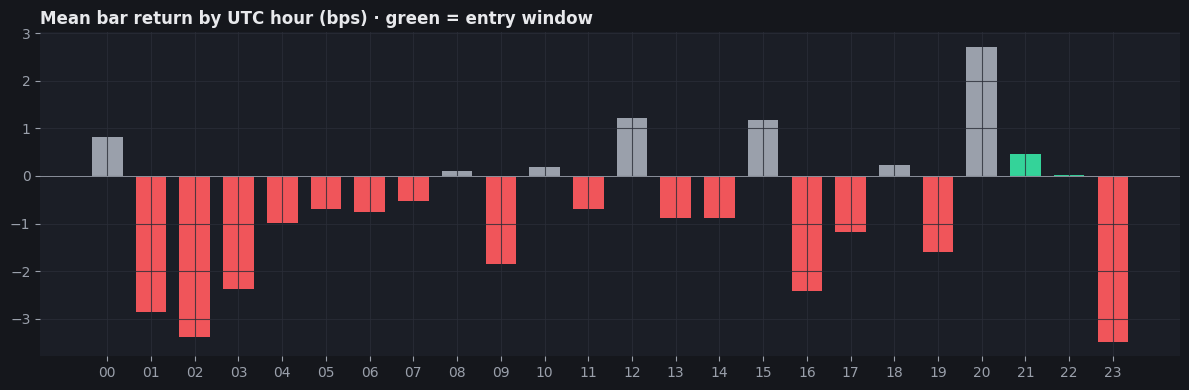

In [42]:
bar_ret = (np.log(df_raw["close"] / df_raw["open"]) * 1e4)          # bps per bar, indexed by bar-open hour (UTC)
hp = bar_ret.groupby(df_raw.index.hour).agg(mean="mean", n="size")
hp["t"] = bar_ret.groupby(df_raw.index.hour).apply(tstat)
hp["rank"] = hp["mean"].rank(ascending=False).astype(int)
win_hours = [(ENTRY_H + k) % 24 for k in range(HOLD)]
print("=" * 70)
print("MEAN BAR RETURN BY UTC HOUR OF THE BAR OPEN (bps, gross of costs and swap)")
print("=" * 70)
display(hp.round(2).T)
win_ret = bar_ret[df_raw.index.hour.isin(win_hours)]
t_win = tstat(win_ret)
top_n = len(win_hours) + 2
print(f"Window bars {win_hours}: mean {win_ret.mean():+.2f} bps per bar, t = {t_win:.2f}, ranks {hp.loc[win_hours, 'rank'].tolist()} of 24")

print("\nCHECKS (4.1):")
check("4.1 Hour profile", f"Entry-window hours are among the top {top_n} hours by mean return", bool((hp.loc[win_hours, "rank"] <= top_n).all()), f"ranks {hp.loc[win_hours, 'rank'].tolist()} of 24")
check("4.1 Hour profile", f"Window bars have a positive mean with t >= 2", win_ret.mean() > 0 and t_win >= 2.0, f"mean {win_ret.mean():+.2f} bps | t = {t_win:.2f}")
yr_pos = win_ret.groupby(win_ret.index.year).mean()
check("4.1 Hour profile", "The window mean is positive in >= 60% of calendar years", float((yr_pos > 0).mean()) >= 0.6, f"{int((yr_pos > 0).sum())}/{len(yr_pos)} years: " + ", ".join(f"{y}:{v:+.1f}" for y, v in yr_pos.items()))

fig, ax = plt.subplots(figsize=(12, 4), facecolor=BG)
dark_ax(ax)
ax.bar(hp.index, hp["mean"], color=[GREEN if h in win_hours else (SUB if m > 0 else RED) for h, m in zip(hp.index, hp["mean"])], width=0.7)
ax.axhline(0, color=SUB, lw=0.6)
ax.set_xticks(range(24)); ax.set_xticklabels([f"{h:02d}" for h in range(24)], color=SUB)
ax.set_title("Mean bar return by UTC hour (bps) · green = entry window", color=TXT, fontweight="bold", loc="left")
plt.tight_layout(); plt.show()

### 4.2 DAY OF THE WEEK (UTC WEEKDAY OF THE ENTRY BAR), GROSS AND NET OF SWAP

ENTRY WEEKDAY (UTC): gross vs net return per trade (%)


,Trades,gross_mean,net_mean,win,swap_nights,net_t
Mon,454,0.077,-0.001,47.577,0.326,-0.022
Tue,454,0.051,-0.027,46.696,0.326,-0.658
Wed,454,0.027,-0.051,46.035,0.326,-1.004
Thu,455,0.030,-0.048,45.714,0.327,-0.995
Fri,455,0.036,-0.078,40.440,0.982,-1.760
Sat,453,0.012,-0.048,43.488,0.000,-1.114
Sun,455,0.021,-0.039,49.890,0.000,-0.733


Kruskal-Wallis across weekdays on gross return: p = 0.777 (descriptive)

CHECKS (4.2):
   [PASS] Every weekday has a positive gross mean (no day carries the edge alone)  ->  gross means: Mon +0.077, Tue +0.051, Wed +0.027, Thu +0.030, Fri +0.036, Sat +0.012, Sun +0.021
   [PASS] Friday gross mean >= mean of the other days (published: Friday is the best day)  ->  Fri +0.036% vs others +0.036%
   [FAIL] Friday is still positive NET of swap (x3 charge)  ->  Fri net -0.078% | swap nights charged avg 0.98


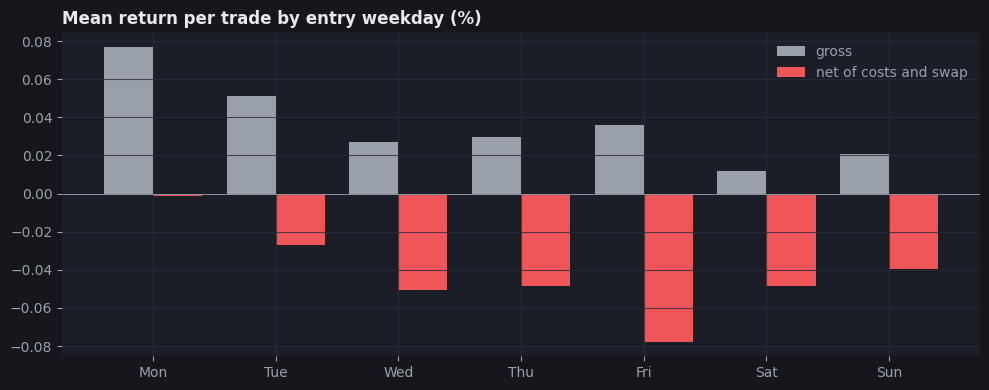

In [43]:
tr_full = eng.run_btcovn_backtest(df, **RULES)
tr_full["era"] = [era_of(y) for y in pd.to_datetime(tr_full["entry_time"]).dt.year]
tr_full["dow"] = pd.to_datetime(tr_full["entry_time"]).dt.dayofweek
tr_full["gross"] = gross_pct(tr_full)
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dw = tr_full.groupby("dow").agg(Trades=("pnl", "size"), gross_mean=("gross", "mean"), net_mean=("pnl", "mean"), win=("win", "mean"), swap_nights=("swap_nights", "mean"))
dw["net_t"] = tr_full.groupby("dow")["pnl"].apply(tstat)
dw["win"] *= 100
dw.index = [names[i] for i in dw.index]
print("=" * 70)
print("ENTRY WEEKDAY (UTC): gross vs net return per trade (%)")
print("=" * 70)
display(dw.round(3))
kw_stat, kw_p = stats.kruskal(*[g["gross"].to_numpy() for _, g in tr_full.groupby("dow")])
print(f"Kruskal-Wallis across weekdays on gross return: p = {kw_p:.3f} (descriptive)")
fri, rest = dw.loc["Fri", "gross_mean"], dw.drop("Fri")["gross_mean"].mean()

print("\nCHECKS (4.2):")
check("4.2 Weekday", "Every weekday has a positive gross mean (no day carries the edge alone)", bool((dw["gross_mean"] > 0).all()), "gross means: " + ", ".join(f"{k} {v:+.3f}" for k, v in dw["gross_mean"].items()))
check("4.2 Weekday", "Friday gross mean >= mean of the other days (published: Friday is the best day)", fri >= rest, f"Fri {fri:+.3f}% vs others {rest:+.3f}%")
check("4.2 Weekday", "Friday is still positive NET of swap (x3 charge)", dw.loc["Fri", "net_mean"] > 0, f"Fri net {dw.loc['Fri', 'net_mean']:+.3f}% | swap nights charged avg {dw.loc['Fri', 'swap_nights']:.2f}")

fig, ax = plt.subplots(figsize=(10, 4), facecolor=BG)
dark_ax(ax)
x = np.arange(len(dw))
ax.bar(x - 0.2, dw["gross_mean"], 0.4, color=SUB, label="gross")
ax.bar(x + 0.2, dw["net_mean"], 0.4, color=[GREEN if v > 0 else RED for v in dw["net_mean"]], label="net of costs and swap")
ax.axhline(0, color=SUB, lw=0.6); ax.set_xticks(x); ax.set_xticklabels(dw.index, color=SUB)
ax.set_title("Mean return per trade by entry weekday (%)", color=TXT, fontweight="bold", loc="left"); ax.legend(frameon=False, labelcolor=SUB)
plt.tight_layout(); plt.show()

### 4.3 DO THE PUBLISHED FILTERS ADD VALUE? NAKED RULE VS UPTREND / HIGH-VOLATILITY (TESTED, NOT CONFIGURED)

In [44]:
filt = {"Naked rule (configured)": {}, "Uptrend only (open 00:00 > SMA)": dict(trend_mode="up"), "High vol only (30d vol > past median)": dict(vol_mode="high"),
        "Uptrend + high vol": dict(trend_mode="up", vol_mode="high")}
rows, tr_f = [], {}
for name, kw in filt.items():
    d_ = prep(df_raw, **kw)
    t = eng.run_btcovn_backtest(d_, **{**RULES, **kw}); tr_f[name] = t
    m = compute_metrics(t, 1.0, 0.0)
    rows.append({"Rules": name, "Trades": m["num_trades"], "Win %": round(m["win_rate"], 1), "PF": round(m["profit_factor"], 3),
                 "Mean net %": round(t["pnl"].mean(), 3), "t-stat": round(tstat(t["pnl"]), 2)})
tbl43 = pd.DataFrame(rows).set_index("Rules")
print("=" * 70 + "\nFILTERS vs NAKED RULE (net of costs and swap, 100% capital)\n" + "=" * 70)
display(tbl43)
base43 = tbl43.iloc[0]
print("\nCHECKS (4.3):")
check("4.3 Filters", "Uptrend filter raises the mean net per trade", tbl43.iloc[1]["Mean net %"] > base43["Mean net %"], f"{tbl43.iloc[1]['Mean net %']:+.3f}% vs {base43['Mean net %']:+.3f}%")
check("4.3 Filters", "High-vol filter raises the mean net per trade", tbl43.iloc[2]["Mean net %"] > base43["Mean net %"], f"{tbl43.iloc[2]['Mean net %']:+.3f}% vs {base43['Mean net %']:+.3f}%")
check("4.3 Filters", "A filter is worth adding only if it keeps >= 200 trades and a t-stat >= 2", bool(((tbl43.iloc[1:]["Trades"] >= 200) & (tbl43.iloc[1:]["t-stat"] >= 2)).any()),
      "; ".join(f"{k}: N={int(r['Trades'])}, t={r['t-stat']:.2f}" for k, r in tbl43.iloc[1:].iterrows()))

FILTERS vs NAKED RULE (net of costs and swap, 100% capital)


,Trades,Win %,PF,Mean net %,t-stat
Rules,,,,,
Naked rule (configured),3180,45.7,0.873,-0.042,-2.35
Uptrend only (open 00:00 > SMA),1639,47.8,0.960,-0.012,-0.52
High vol only (30d vol > past median),939,47.1,0.893,-0.045,-1.08
Uptrend + high vol,447,52.6,1.148,0.057,0.94



CHECKS (4.3):
   [PASS] Uptrend filter raises the mean net per trade  ->  -0.012% vs -0.042%
   [FAIL] High-vol filter raises the mean net per trade  ->  -0.045% vs -0.042%
   [FAIL] A filter is worth adding only if it keeps >= 200 trades and a t-stat >= 2  ->  Uptrend only (open 00:00 > SMA): N=1639, t=-0.52; High vol only (30d vol > past median): N=939, t=-1.08; Uptrend + high vol: N=447, t=0.94


'FAIL'

### 4.4 SWAP: HOW MUCH OF THE EDGE DOES THE ROLLOVER EAT?
The window straddles the 17:00 New York rollover when the entry is at 21:00 UTC in winter (EST), and sits exactly on it in summer (EDT). Friday is charged x3 in the MT5 table.

In [45]:
sr = eng.swap_report(tr_full)
g = tr_full.groupby(tr_full["swap_nights"].round().astype(int)).agg(Trades=("pnl", "size"), gross_mean=("gross", "mean"), net_mean=("pnl", "mean"), win=("win", "mean"))
g["net_t"] = tr_full.groupby(tr_full["swap_nights"].round().astype(int))["pnl"].apply(tstat)
g["win"] *= 100
g.index = [{0: "no swap charged", 1: "1 night charged", 3: "Friday x3 charged"}.get(i, f"{i} nights") for i in g.index]
print("=" * 70)
print(f"SWAP DRAG · swap long {eng.ENGINE_DEFAULTS['swap_long_pct_annual']:g}%/yr = {eng.ENGINE_DEFAULTS['swap_long_pct_annual'] / 365:.4f}% per night")
print("=" * 70)
display(g.round(3))
gross_mean = float(tr_full["gross"].mean())
drag_share = sr["avg_swap_drag_pct"] / gross_mean if gross_mean > 0 else np.inf
print(f"Trades crossing a charged rollover: {sr['pct_crossing']:.1%} | average swap drag {sr['avg_swap_drag_pct']:.4f}% per trade = {drag_share:.0%} of the average gross return ({gross_mean:.4f}%)")
print(f"Average net {sr['avg_net_pnl_pct']:+.4f}% | average gross of swap {sr['avg_gross_of_swap_pct']:+.4f}% | average drag on Friday-x3 trades {sr['avg_drag_friday_pct']:.4f}%")

print("\nCHECKS (4.4):")
check("4.4 Swap", f"Average swap drag <= {SWAP_DRAG_MAX:.0%} of the average gross return", drag_share <= SWAP_DRAG_MAX, f"{drag_share:.0%} (drag {sr['avg_swap_drag_pct']:.4f}% vs gross {gross_mean:.4f}%)")
for lab in ("1 night charged", "Friday x3 charged"):
    if lab in g.index:
        check("4.4 Swap", f"Trades with '{lab}' stay positive net of swap", g.loc[lab, "net_mean"] > 0, f"net {g.loc[lab, 'net_mean']:+.3f}% (gross {g.loc[lab, 'gross_mean']:+.3f}%, N={int(g.loc[lab, 'Trades'])})")
    else:
        check("4.4 Swap", f"Trades with '{lab}' stay positive net of swap", None, "no such trades in this sample")

SWAP DRAG · swap long 20%/yr = 0.0548% per night


,Trades,gross_mean,net_mean,win,net_t
no swap charged,2438,0.061,0.001,47.211,0.026
1 night charged,593,-0.043,-0.158,42.327,-3.832
Friday x3 charged,149,-0.046,-0.270,34.228,-2.948


Trades crossing a charged rollover: 23.3% | average swap drag 0.0179% per trade = 50% of the average gross return (0.0361%)
Average net -0.0418% | average gross of swap -0.0239% | average drag on Friday-x3 trades 0.1644%

CHECKS (4.4):
   [FAIL] Average swap drag <= 25% of the average gross return  ->  50% (drag 0.0179% vs gross 0.0361%)
   [FAIL] Trades with '1 night charged' stay positive net of swap  ->  net -0.158% (gross -0.043%, N=593)
   [FAIL] Trades with 'Friday x3 charged' stay positive net of swap  ->  net -0.270% (gross -0.046%, N=149)


### 4.5 TAIL RISK AND STOP SWEEP: HOW BAD CAN A 2-HOUR TRADE GET, AND WHAT DOES A STOP COST?

In [46]:
rows, tr_stop = [], {}
for sp in (0.0, 0.5, 1.0, 1.5, 2.0, 3.0):
    t = eng.run_btcovn_backtest(df, **{**RULES, "stop_pct": sp}); tr_stop[sp] = t
    s = summarize(t)
    rows.append({"stop %": sp, "Trades": s["n"], "PF": round(s["pf"], 3), "Mean net %": round(s["mean"], 4), "t": round(s["t"], 2), "Win %": round(s["win"], 1),
                 "Stopped %": round((t["exit_reason"] != "time").mean() * 100, 1), "Worst trade %": round(t["pnl"].min(), 2)})
stop_tbl = pd.DataFrame(rows).set_index("stop %")
display(stop_tbl)
worst = tr_full.nsmallest(5, "pnl")[["entry_time", "entry_price", "exit_price", "pnl", "pnl_usd", "exit_reason"]]
print("Five worst trades (no stop):"); display(worst.round(3))
worst_move = eng.worst_adverse_move(df, tr_full)
worst_move_pct = worst_move / float(tr_full.loc[tr_full["pnl_usd"].idxmin(), "entry_price"]) * 100 if len(tr_full) else np.nan
print(f"Worst adverse excursion in a 2-hour window: {worst_move:,.2f} price units")

print("\nCHECKS (4.5):")
check("4.5 Tail", "Worst single trade loses <= 10% (2-hour crash tail)", -tr_full["pnl"].min() <= 10.0, f"worst {tr_full['pnl'].min():.2f}%")
check("4.5 Tail", "A 2% stop keeps >= 80% of the no-stop PF", stop_tbl.loc[2.0, "PF"] >= 0.8 * stop_tbl.loc[0.0, "PF"], f"PF {stop_tbl.loc[2.0, 'PF']:.3f} vs {stop_tbl.loc[0.0, 'PF']:.3f}")
check("4.5 Tail", "A 1% stop keeps >= 80% of the no-stop PF (the stop that would fit a tiny allocation)", stop_tbl.loc[1.0, "PF"] >= 0.8 * stop_tbl.loc[0.0, "PF"], f"PF {stop_tbl.loc[1.0, 'PF']:.3f} vs {stop_tbl.loc[0.0, 'PF']:.3f}")

,Trades,PF,Mean net %,t,Win %,Stopped %,Worst trade %
stop %,,,,,,,
0.0,3180,0.873,-0.0418,-2.35,45.7,0.0,-10.23
0.5,3180,0.557,-0.1452,-12.40,30.3,52.3,-0.74
1.0,3180,0.576,-0.1703,-11.40,38.3,28.8,-1.22
1.5,3180,0.592,-0.1742,-10.37,41.3,17.7,-1.72
2.0,3180,0.598,-0.1747,-9.72,42.8,11.7,-2.22
3.0,3180,0.626,-0.1622,-8.28,44.0,6.2,-3.22


Five worst trades (no stop):


,entry_time,entry_price,exit_price,pnl,pnl_usd,exit_reason
284,2018-11-24 21:00:00,4192.64,3766.29,-10.229,-426.35,time
759,2020-03-15 21:00:00,5922.96,5344.51,-9.826,-578.45,time
0,2018-01-21 21:00:00,11144.56,10331.00,-7.360,-813.56,time
436,2019-04-25 21:00:00,5496.01,5130.16,-6.717,-365.85,time
414,2019-04-03 21:00:00,5321.12,4974.64,-6.571,-346.48,time


Worst adverse excursion in a 2-hour window: 9,220.44 price units

CHECKS (4.5):
   [FAIL] Worst single trade loses <= 10% (2-hour crash tail)  ->  worst -10.23%
   [FAIL] A 2% stop keeps >= 80% of the no-stop PF  ->  PF 0.598 vs 0.873
   [FAIL] A 1% stop keeps >= 80% of the no-stop PF (the stop that would fit a tiny allocation)  ->  PF 0.576 vs 0.873


'FAIL'

## 5. BASELINE BACKTEST WITH FROZEN RULES

PERFORMANCE SUMMARY (NET OF 3 BPS PER SIDE + SWAP · hourly MTM drawdown, Sharpe on daily returns x365)


,Period,Sizing,Trades,Win Rate,Profit Factor,Expectancy,Total Return,CAGR,Sharpe,Max Drawdown
0,In-Sample (2018-2023),100% Capital,1780,45.7%,0.828,-0.071%,-74.9%,-24.2%,-1.12,-79.96%
1,In-Sample (2018-2023),100% Capital (robot),1780,45.7%,0.828,-0.071%,-74.9%,-24.2%,-1.12,-79.96%
2,Out-of-Sample (2023-2026),100% Capital,1400,45.6%,0.977,-0.005%,-10.0%,-2.7%,-0.15,-28.87%
3,Out-of-Sample (2023-2026),100% Capital (robot),1400,45.6%,0.977,-0.005%,-10.0%,-2.7%,-0.15,-28.87%
4,Full Period (2018-2026),100% Capital,3180,45.7%,0.873,-0.042%,-77.4%,-15.5%,-0.79,-82.49%
5,Full Period (2018-2026),100% Capital (robot),3180,45.7%,0.873,-0.042%,-77.4%,-15.5%,-0.79,-82.49%


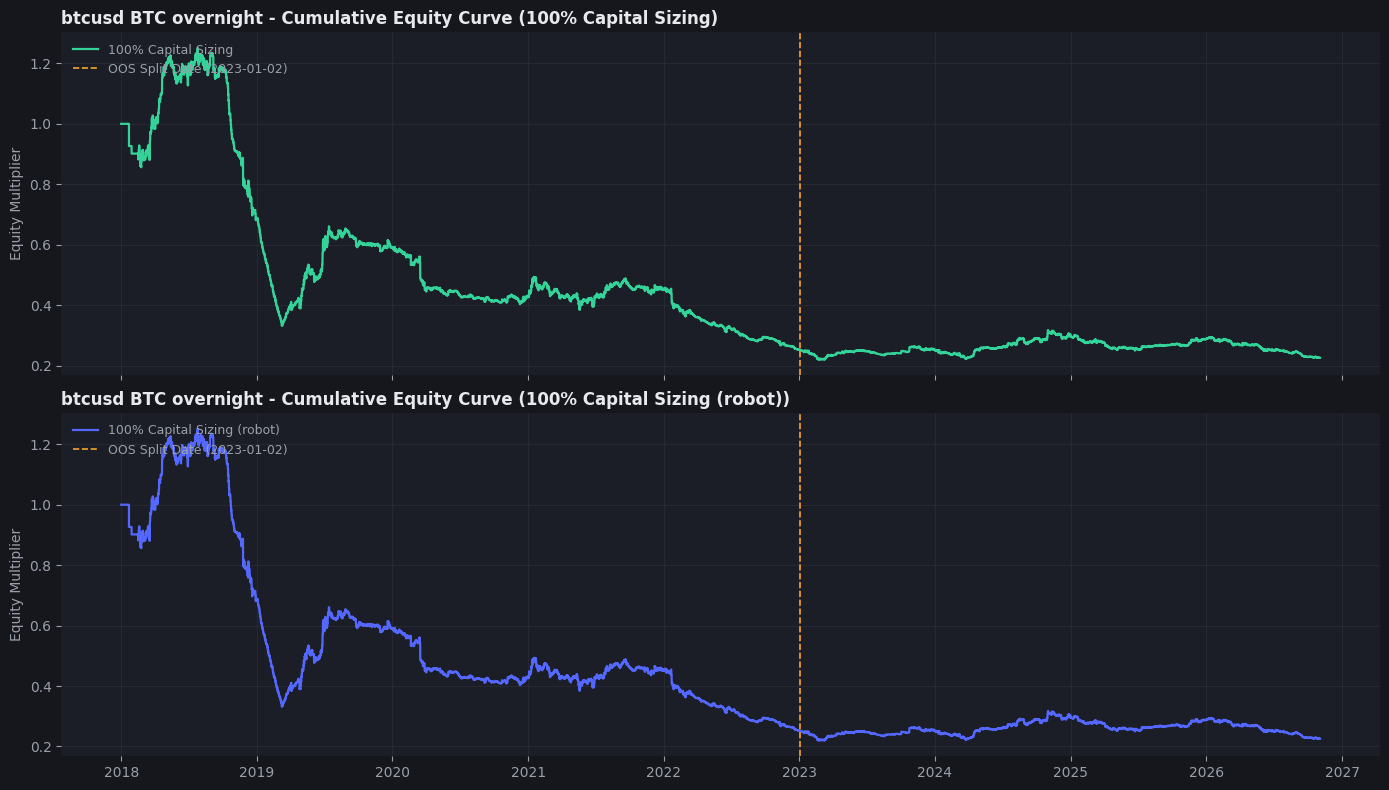

btcusd price change: +454% | strategy profit: -77,431 (-77.4% of 100,000) | buy & hold profit: 453,816 | time in market: 8.3%

CHECKS (5):
   [FAIL] Profit Factor, full period >= 1.15  ->  PF = 0.873
   [FAIL] Profit Factor, IS >= 1.15  ->  PF = 0.828
   [FAIL] Profit Factor, OOS >= 1.15  ->  PF = 0.977
   [PASS] OOS does not degrade vs IS (OOS PF >= 50% of IS PF)  ->  OOS 0.977 vs IS 0.828
   [FAIL] t-stat of the mean trade >= 2  ->  t = -2.35
   [PASS] Trades, full period >= 1000  ->  3180 trades
   [PASS] Trades, OOS >= 150  ->  1400 trades
   [FAIL] Expectancy > 0 in IS and OOS (net of costs and swap)  ->  IS -0.071% | OOS -0.005%


'FAIL'

In [47]:
trades_is  = eng.run_btcovn_backtest(df_is,  **RULES)
trades_oos = eng.run_btcovn_backtest(df_oos, **RULES)
trades_all = eng.run_btcovn_backtest(df,     **RULES)

def sized(t, sizing):
    return t if sizing == "capital" else t.assign(pnl=t["pnl_frac"], win=t["pnl_frac"] > 0)

def perf_row(t, price_df, period, sizing):
    m = compute_metrics(sized(t, sizing), contract_multiplier=1.0, cost_per_trade=0.0)
    ret = eng.hourly_returns(price_df, t, sizing=sizing)
    eq = (1.0 + ret).cumprod()
    yrs = (price_df.index[-1] - price_df.index[0]).days / 365.25
    return {"Period": period, "Sizing": "100% Capital" if sizing == "capital" else f"{SIZE_FRAC:.0%} Capital (robot)",
            "Trades": m["num_trades"], "Win Rate": f"{m['win_rate']:.1f}%", "Profit Factor": f"{m['profit_factor']:.3f}",
            "Expectancy": f"{m['expectancy']:.3f}%", "Total Return": f"{(eq.iloc[-1] - 1) * 100:.1f}%",
            "CAGR": f"{((eq.iloc[-1] ** (1 / yrs)) - 1) * 100:.1f}%" if yrs > 0 else "n/a",
            "Sharpe": f"{sharpe_ratio(dly(ret), periods_per_year=PPY):.2f}", "Max Drawdown": f"{max_drawdown(eq) * 100:.2f}%"}

periods = [(f"In-Sample ({df_is.index[0].year}-{df_is.index[-1].year})", trades_is, df_is),
           (f"Out-of-Sample ({df_oos.index[0].year}-{df_oos.index[-1].year})", trades_oos, df_oos),
           (f"Full Period ({df.index[0].year}-{df.index[-1].year})", trades_all, df)]
perf_table = pd.DataFrame([perf_row(t, d, name, s) for name, t, d in periods for s in ("capital", "fraction")])
print("=" * 80)
print(f"PERFORMANCE SUMMARY (NET OF {COST_BPS:g} BPS PER SIDE + SWAP · hourly MTM drawdown, Sharpe on daily returns x{PPY})")
print("=" * 80)
display(perf_table)

ret_cap = eng.hourly_returns(df, trades_all, sizing="capital")
ret_fr = eng.hourly_returns(df, trades_all, sizing="fraction")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, facecolor=BG)
for ax, r, col, lab in ((ax1, ret_cap, GREEN, "100% Capital Sizing"), (ax2, ret_fr, "#5468ff", f"{SIZE_FRAC:.0%} Capital Sizing (robot)")):
    dark_ax(ax)
    ax.plot(r.index, (1 + r).cumprod(), color=col, lw=1.6, label=lab)
    ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.2, label=f"OOS Split Date ({oos_start:%Y-%m-%d})")
    ax.set_title(f"{TICKER} BTC overnight - Cumulative Equity Curve ({lab})", color=TXT, fontweight="bold", loc="left")
    ax.set_ylabel("Equity Multiplier", color=SUB); ax.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

profit_usd = CAPITAL * ((1.0 + ret_fr).cumprod() - 1.0)
buy_hold = CAPITAL * (df["close"] / df["close"].iloc[0] - 1.0)
in_market = float(trades_all["bars"].sum()) / len(df)
print(f"{TICKER} price change: {(df['close'].iloc[-1] / df['close'].iloc[0] - 1) * 100:+,.0f}% | strategy profit: {profit_usd.iloc[-1]:,.0f} "
      f"({profit_usd.iloc[-1] / CAPITAL * 100:+.1f}% of {CAPITAL:,.0f}) | buy & hold profit: {buy_hold.iloc[-1]:,.0f} | time in market: {in_market * 100:.1f}%")

print("\nCHECKS (5):")
m_is, m_oos, m_all = (compute_metrics(t, 1.0, 0.0) for t in (trades_is, trades_oos, trades_all))
t_all = tstat(trades_all["pnl"])
check("5. Baseline", f"Profit Factor, full period >= {PF_MIN:g}", m_all["profit_factor"] >= PF_MIN, f"PF = {m_all['profit_factor']:.3f}")
check("5. Baseline", f"Profit Factor, IS >= {PF_MIN:g}", m_is["profit_factor"] >= PF_MIN, f"PF = {m_is['profit_factor']:.3f}")
check("5. Baseline", f"Profit Factor, OOS >= {PF_MIN:g}", m_oos["profit_factor"] >= PF_MIN, f"PF = {m_oos['profit_factor']:.3f}")
check("5. Baseline", "OOS does not degrade vs IS (OOS PF >= 50% of IS PF)", m_oos["profit_factor"] >= 0.5 * m_is["profit_factor"], f"OOS {m_oos['profit_factor']:.3f} vs IS {m_is['profit_factor']:.3f}")
check("5. Baseline", f"t-stat of the mean trade >= {T_MIN:g}", t_all >= T_MIN, f"t = {t_all:.2f}")
check("5. Baseline", f"Trades, full period >= {N_MIN}", m_all["num_trades"] >= N_MIN, f"{m_all['num_trades']} trades")
check("5. Baseline", f"Trades, OOS >= {N_OOS_MIN}", m_oos["num_trades"] >= N_OOS_MIN, f"{m_oos['num_trades']} trades")
check("5. Baseline", "Expectancy > 0 in IS and OOS (net of costs and swap)", m_is["expectancy"] > 0 and m_oos["expectancy"] > 0, f"IS {m_is['expectancy']:+.3f}% | OOS {m_oos['expectancy']:+.3f}%")

## 5.1 LOT-ADJUSTED SIZING AND HARD LIMIT (CFD)
The drawdown is measured on hourly closes and, more strictly, **intrabar** (candle extremes, gap exits included), which is what a broker kill-switch sees. For a vehicle variant `CAPITAL` is the Allocation Account and the minimum lot is already multiplied by the copy multiplier.

HARD LIMIT -7% · LOT-ADJUSTED SIZING (min lot 0.1, step 0.1, 1 coin per lot)


,Sizing,Trades taken,Total Return,Max DD (hourly MTM),Max DD (intrabar),Headroom (intrabar),Hard limit
0,100% ideal fraction,3180,-77.4%,-82.49%,-83.26%,-76.26 pts,FAIL
1,"Lot-adjusted (capital 100,000)",3180,-77.2%,-82.30%,-82.92%,-75.92 pts,FAIL


The minimum lot at 76,757.46 weighs 0.08x of the capital (100,000)
Minimum capital so the minimum lot weighs <= 100% at 76,757.46: 7,676
Minimum capital so the minimum lot survives the worst historical adverse move inside -7%: 13,172
Largest fixed fraction that keeps the intrabar drawdown inside -7%: 4.3% (configured: 100%)

CHECKS (5.1):
   [FAIL] 100% ideal fraction stays inside -7% (intrabar)  ->  max DD -83.26% | headroom -76.26 pts
   [FAIL] Lot-adjusted sizing stays inside -7% (intrabar)  ->  max DD -82.92% | headroom -75.92 pts
   [FAIL] Configured fraction <= largest fraction allowed by the limit  ->  100% vs 4.3%
   [PASS] Capital >= minimum capital for the minimum lot  ->  100,000 vs 7,676
   [PASS] Capital >= minimum capital for the worst historical adverse move  ->  100,000 vs 13,172
   [PASS] Every trade is executable with the minimum lot  ->  3180 of 3180 trades taken


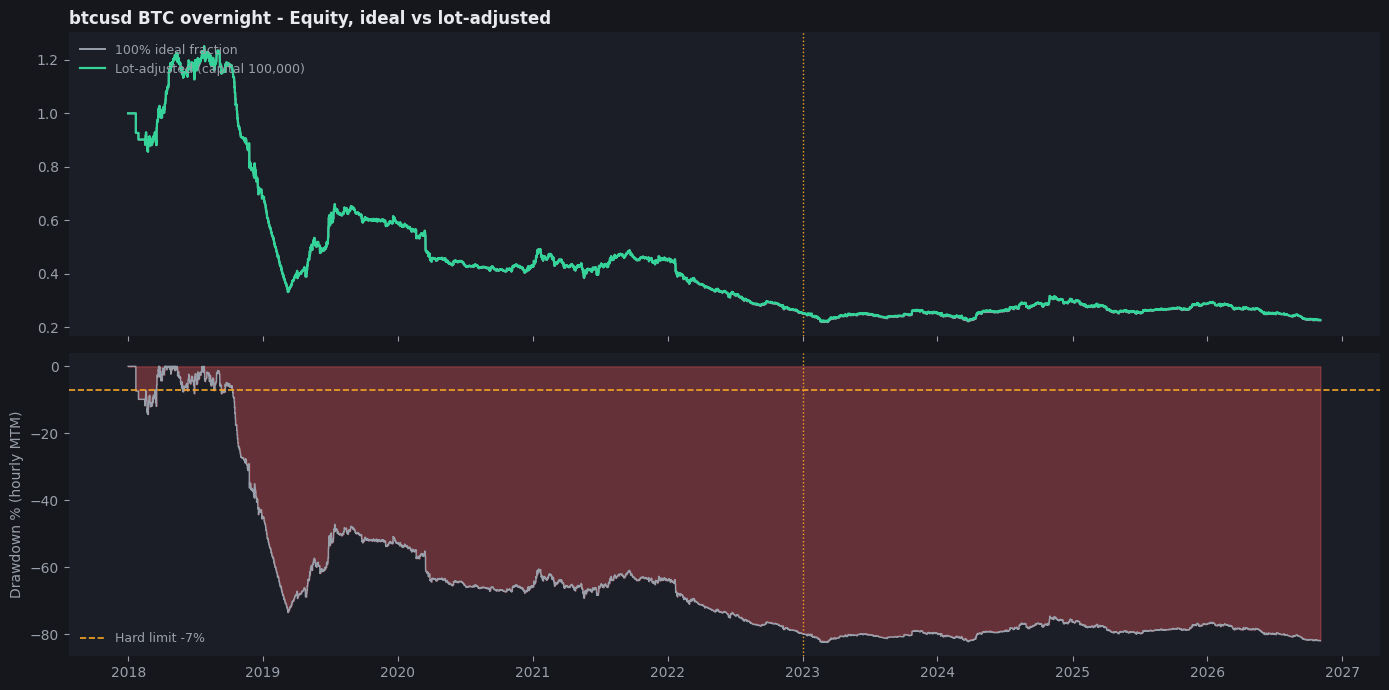

In [48]:
last_price = float(df["close"].iloc[-1])
min_capital = eng.min_capital_for_target(last_price, SIZE_FRAC)
max_frac = eng.max_fraction_for_limit(df, trades_all, HARD_LIMIT)
lot_sizes = eng.cfd_trade_sizes(trades_all, CAPITAL, SIZE_FRAC)
hourly_ideal = eng.hourly_returns(df, trades_all, sizing="fraction")
hourly_lot = eng.hourly_returns(df, trades_all, sizing=lot_sizes["size_fraction"].to_numpy())

def drawdown_series(r):
    eq = (1.0 + r).cumprod()
    return eq / np.maximum(eq.cummax(), 1.0) - 1.0

def limit_row(label, ret, sizing, n_taken):
    rep, rep_ib = eng.hard_limit_report(ret, HARD_LIMIT), eng.hard_limit_report_intrabar(df, trades_all, HARD_LIMIT, sizing)
    return {"Sizing": label, "Trades taken": n_taken, "Total Return": f"{((1.0 + ret).prod() - 1.0) * 100:.1f}%",
            "Max DD (hourly MTM)": f"{rep['max_dd'] * 100:.2f}%", "Max DD (intrabar)": f"{rep_ib['max_dd'] * 100:.2f}%",
            "Headroom (intrabar)": f"{rep_ib['headroom'] * 100:+.2f} pts", "Hard limit": "PASS" if rep_ib["passed"] else "FAIL"}

limit_table = pd.DataFrame([limit_row(f"{SIZE_FRAC:.0%} ideal fraction", hourly_ideal, "fraction", len(trades_all)),
                            limit_row(f"Lot-adjusted (capital {CAPITAL:,.0f})", hourly_lot, lot_sizes["size_fraction"].to_numpy(), int(lot_sizes["taken"].sum()))])
print("=" * 80)
print(f"HARD LIMIT -{HARD_LIMIT:.0%} · LOT-ADJUSTED SIZING (min lot {MIN_LOT:g}, step {LOT_STEP:g}, {CONTRACT_SIZE:g} coin per lot)")
print("=" * 80)
display(limit_table)
worst_move = eng.worst_adverse_move(df, trades_all)
min_cap_gap = MIN_LOT * CONTRACT_SIZE * worst_move * eng.ENGINE_DEFAULTS["quote_to_account"] / HARD_LIMIT
min_lot_weight = MIN_LOT * CONTRACT_SIZE * last_price * eng.ENGINE_DEFAULTS["quote_to_account"] / CAPITAL
print(f"The minimum lot at {last_price:,.2f} weighs {min_lot_weight:.2f}x of the capital ({CAPITAL:,.0f})")
print(f"Minimum capital so the minimum lot weighs <= {SIZE_FRAC:.0%} at {last_price:,.2f}: {min_capital:,.0f}")
print(f"Minimum capital so the minimum lot survives the worst historical adverse move inside -{HARD_LIMIT:.0%}: {min_cap_gap:,.0f}")
print(f"Largest fixed fraction that keeps the intrabar drawdown inside -{HARD_LIMIT:.0%}: {max_frac:.1%} (configured: {SIZE_FRAC:.0%})")

print("\nCHECKS (5.1):")
rep_ideal = eng.hard_limit_report_intrabar(df, trades_all, HARD_LIMIT, "fraction")
rep_lot = eng.hard_limit_report_intrabar(df, trades_all, HARD_LIMIT, lot_sizes["size_fraction"].to_numpy())
check("5.1 Hard limit", f"{SIZE_FRAC:.0%} ideal fraction stays inside -{HARD_LIMIT:.0%} (intrabar)", rep_ideal["passed"], f"max DD {rep_ideal['max_dd'] * 100:.2f}% | headroom {rep_ideal['headroom'] * 100:+.2f} pts")
check("5.1 Hard limit", f"Lot-adjusted sizing stays inside -{HARD_LIMIT:.0%} (intrabar)", rep_lot["passed"], f"max DD {rep_lot['max_dd'] * 100:.2f}% | headroom {rep_lot['headroom'] * 100:+.2f} pts")
check("5.1 Hard limit", "Configured fraction <= largest fraction allowed by the limit", SIZE_FRAC <= max_frac, f"{SIZE_FRAC:.0%} vs {max_frac:.1%}")
check("5.1 Hard limit", "Capital >= minimum capital for the minimum lot", CAPITAL >= min_capital, f"{CAPITAL:,.0f} vs {min_capital:,.0f}")
check("5.1 Hard limit", "Capital >= minimum capital for the worst historical adverse move", CAPITAL >= min_cap_gap, f"{CAPITAL:,.0f} vs {min_cap_gap:,.0f}")
check("5.1 Hard limit", "Every trade is executable with the minimum lot", int(lot_sizes["taken"].sum()) == len(trades_all), f"{int(lot_sizes['taken'].sum())} of {len(trades_all)} trades taken")

dd_ideal, dd_lot = drawdown_series(hourly_ideal), drawdown_series(hourly_lot)
fig, (ax_eq, ax_dd) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, facecolor=BG)
for ax in (ax_eq, ax_dd):
    dark_ax(ax); ax.grid(False); ax.axvline(oos_start, color=ORANGE, ls=":", lw=1.0)
ax_eq.plot(hourly_ideal.index, (1.0 + hourly_ideal).cumprod(), color=SUB, lw=1.4, label=f"{SIZE_FRAC:.0%} ideal fraction")
ax_eq.plot(hourly_lot.index, (1.0 + hourly_lot).cumprod(), color=GREEN, lw=1.6, label=f"Lot-adjusted (capital {CAPITAL:,.0f})")
ax_eq.set_title(f"{TICKER} BTC overnight - Equity, ideal vs lot-adjusted", color=TXT, fontweight="bold", loc="left")
ax_eq.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="upper left")
ax_dd.plot(dd_ideal.index, dd_ideal * 100, color=SUB, lw=1.0)
ax_dd.fill_between(dd_lot.index, dd_lot * 100, 0, color=RED, alpha=0.35)
ax_dd.axhline(-HARD_LIMIT * 100, color=ORANGE, ls="--", lw=1.2, label=f"Hard limit -{HARD_LIMIT:.0%}")
ax_dd.set_ylabel("Drawdown % (hourly MTM)", color=SUB); ax_dd.legend(frameon=False, labelcolor=SUB, fontsize=9, loc="lower left")
plt.tight_layout(); plt.show()

## 5.2 ANNUAL RETURNS AND HARD LIMIT CHECK

ANNUAL RETURNS · LOT-ADJUSTED · HARD LIMIT -7% · * = partial year


,year,ret,mdd,breach,partial
0,2018,-31.1%,-45.5%,True,False
1,2019,-14.1%,-51.8%,True,False
2,2020,-27.7%,-31.8%,True,False
3,2021,+5.7%,-21.8%,True,False
4,2022,-44.1%,-44.6%,True,False
5,2023,-0.3%,-12.6%,True,False
6,2024,+17.9%,-11.2%,True,False
7,2025,-2.7%,-16.3%,True,False
8,2026,-21.3%,-22.9%,True,True


Steps below the limit: 71745 | first breach: 2018-01-21 22:00:00

CHECKS (5.2):
   [FAIL] No calendar year breaches the hard limit  ->  years in breach: [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026] | worst year DD -51.8%
   [FAIL] >= 60% of full calendar years are profitable  ->  2/8 full years positive | non-positive: 2018 (-31.1%), 2019 (-14.1%), 2020 (-27.7%), 2022 (-44.1%), 2023 (-0.3%), 2025 (-2.7%)


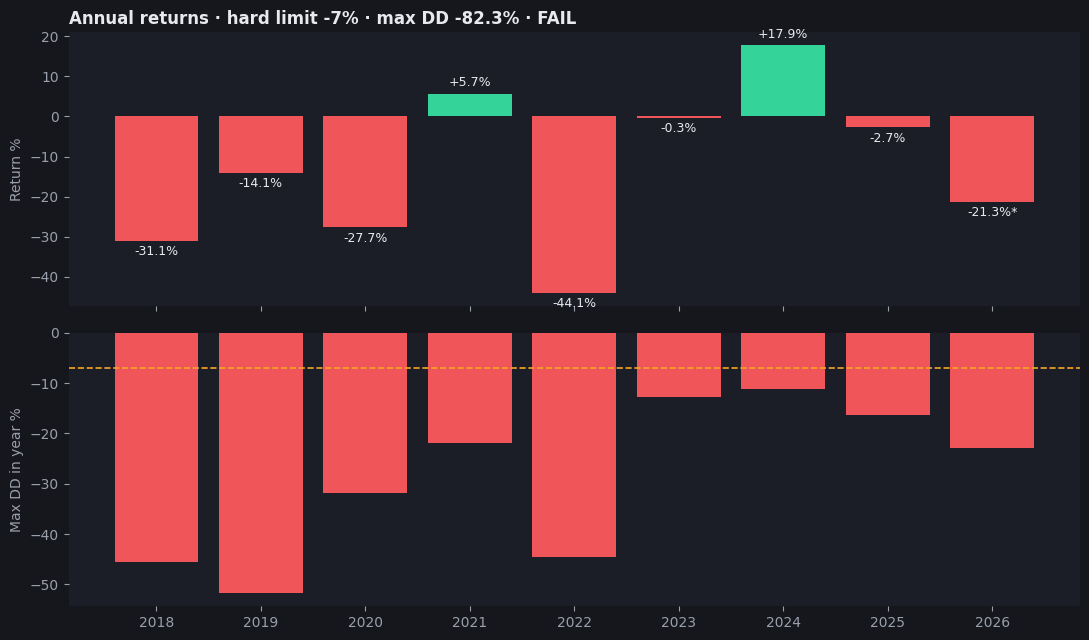

In [49]:
def plot_annual_returns(annual, report, hard_limit):
    fig, (ax_ret, ax_dd) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, facecolor=BG)
    years = annual["year"].astype(str).to_numpy()
    bars = ax_ret.bar(years, annual["ret"] * 100, color=[GREEN if v >= 0 else RED for v in annual["ret"]])
    ax_dd.bar(years, annual["mdd"] * 100, color=[RED if b else SUB for b in annual["breach"]])
    ax_dd.axhline(-hard_limit * 100, color=ORANGE, ls="--", lw=1.2)
    for ax in (ax_ret, ax_dd):
        dark_ax(ax); ax.grid(False)
    for rect, value, partial in zip(bars, annual["ret"], annual["partial"]):
        ax_ret.annotate(f"{value:+.1%}" + ("*" if partial else ""), (rect.get_x() + rect.get_width() / 2, value * 100),
                        xytext=(0, 3 if value >= 0 else -3), textcoords="offset points", ha="center",
                        va="bottom" if value >= 0 else "top", color=TXT, fontsize=9)
    ax_ret.set_title(f"Annual returns · hard limit -{hard_limit:.0%} · max DD {report['max_dd']:.1%} · {'PASS' if report['passed'] else 'FAIL'}", color=TXT, fontweight="bold", loc="left")
    ax_ret.set_ylabel("Return %", color=SUB); ax_dd.set_ylabel("Max DD in year %", color=SUB)
    plt.tight_layout(); plt.show()

annual = eng.annual_returns(hourly_lot, trades_all, HARD_LIMIT)
report_annual = eng.hard_limit_report(hourly_lot, HARD_LIMIT)
print("=" * 80)
print(f"ANNUAL RETURNS · LOT-ADJUSTED · HARD LIMIT -{HARD_LIMIT:.0%} · * = partial year")
print("=" * 80)
display(annual.style.format({"ret": "{:+.1%}", "mdd": "{:.1%}"}))
print(f"Steps below the limit: {report_annual['steps_in_breach']} | first breach: {report_annual['first_breach']}")

print("\nCHECKS (5.2):")
full_y = annual[~annual["partial"]]
neg = full_y[full_y["ret"] <= 0]
n_pos = len(full_y) - len(neg)
breach_years = annual.loc[annual["breach"], "year"].astype(int).tolist()
check("5.2 Annual", "No calendar year breaches the hard limit", not annual["breach"].any(), f"years in breach: {breach_years if breach_years else 'none'} | worst year DD {annual['mdd'].min() * 100:.1f}%")
check("5.2 Annual", f">= {YEARS_POS_MIN:.0%} of full calendar years are profitable", len(full_y) > 0 and n_pos / len(full_y) >= YEARS_POS_MIN,
      f"{n_pos}/{len(full_y)} full years positive" + (" | non-positive: " + ", ".join(f"{int(y)} ({r:+.1%})" for y, r in zip(neg["year"], neg["ret"])) if len(neg) else ""))
plot_annual_returns(annual, report_annual, HARD_LIMIT)

## 6. SANITY CHECKS & VERIFICATION

In [50]:
print("=" * 70)
print("SANITY CHECKS & REPRODUCIBILITY")
print("=" * 70)

# 1. No lookahead + execution model (violations are collected, not asserted, so the notebook keeps running)
violations, prev_end = [], None
STOP = float(RULES["stop_pct"])
for idx_, r in trades_all.iterrows():
    et, xt = pd.Timestamp(r["entry_time"]), pd.Timestamp(r["exit_time"])
    i_e, i_s = int(r["i_ent"]), int(r["i_sal"])
    bar_e, bar_s = df.iloc[i_e], df.iloc[i_s]
    if df.index[i_e] != et:
        violations.append(f"trade {idx_}: i_ent misaligned with entry_time")
    if bar_e["hour"] != ENTRY_H:
        violations.append(f"trade {idx_}: entry is not at {ENTRY_H:02d}:00 UTC")
    if not np.isclose(r["entry_price"], bar_e["open"]):
        violations.append(f"trade {idx_}: entry price is not the open of the entry bar")
    if r["exit_reason"] == "time" and not np.isclose(r["exit_price"], bar_s["close"]):
        violations.append(f"trade {idx_}: time exit is not the close of the last held bar")
    if r["exit_reason"] == "time" and (i_s - i_e + 1) != HOLD:
        violations.append(f"trade {idx_}: holding time differs from hold_hours")
    if not (df["low"].iloc[i_e:i_s + 1].min() - 1e-9 <= r["exit_price"] <= df["high"].iloc[i_e:i_s + 1].max() + 1e-9):
        violations.append(f"trade {idx_}: exit price outside the candle range")
    if STOP > 0 and r["exit_reason"] in ("stop", "stop_entry_bar") and r["exit_price"] < r["entry_price"] * (1 - STOP / 100) - 1e-9:
        violations.append(f"trade {idx_}: loss beyond the stop without a gap")
    if prev_end is not None and i_e <= prev_end:
        violations.append(f"trade {idx_}: overlaps the previous trade")
    prev_end = i_s
print(f"Sanity Check 1: entry = open of the {ENTRY_H:02d}:00 UTC bar, time exit = close of the last held bar, exit inside the candle, no overlap ({len(trades_all)} trades).")
check("6. Sanity", "No lookahead and execution model respected on every trade", not violations,
      f"{len(trades_all)} trades checked" + (f" | {len(violations)} violations, first: {violations[0]}" if violations else ""))

# 2. Trade distribution per calendar year (full years only)
trades_all["year"] = pd.to_datetime(trades_all["entry_time"]).dt.year
tpy = trades_all.groupby("year").size()
full_years = [y for y in range(df.index[0].year, df.index[-1].year + 1) if pd.Timestamp(f"{y}-01-07") >= df.index[0] and pd.Timestamp(f"{y}-12-24") <= df.index[-1]]
tpy_full = tpy.reindex(full_years, fill_value=0)
print("\nSanity Check 2: Trade Frequency per Year:")
print(f"   - Average trades per year: {tpy.mean():.1f} | Min (full years): {tpy_full.min()} ({tpy_full.idxmin()}) | Max: {tpy.max()} ({tpy.idxmax()})")
check("6. Sanity", f"Every full calendar year has >= {MIN_TRADES_PER_YEAR} trades", (tpy_full >= MIN_TRADES_PER_YEAR).all(), f"min {tpy_full.min()} ({tpy_full.idxmin()}) | max {tpy_full.max()} over {len(tpy_full)} full years")

# 3. MTM paths reproduce the trade returns exactly
paths = eng.trade_mtm_paths(df, trades_all, sizing="capital")
err = max(abs(np.prod(1 + p) - (1 + pnl / 100)) for p, pnl in zip(paths, trades_all["pnl"]))
print(f"\nSanity Check 3: MTM paths telescope to trade returns (max abs error {err:.2e}).")
check("6. Sanity", "MTM paths telescope to the trade returns (error < 1e-9)", err < 1e-9, f"max abs error {err:.2e}")

# 4. Indicators on the FULL history = indicators on a truncated history (the signal never uses the future)
cut = len(df) - 24 * 180
tr_cut = eng.run_btcovn_backtest(prep(df_raw.iloc[:cut]), **RULES)
a_ = trades_all[trades_all["i_sal"] < cut - 5][["entry_time", "exit_time", "entry_price", "exit_price"]].reset_index(drop=True)
b_ = tr_cut[tr_cut["i_sal"] < cut - 5][["entry_time", "exit_time", "entry_price", "exit_price"]].reset_index(drop=True)
check("6. Sanity", "No lookahead: truncating the last 6 months does not change earlier trades", a_.equals(b_), f"{len(a_)} trades compared")
# same test with the filters ON (they use the 00:00 UTC trend and the expanding vol median)
fkw = dict(trend_mode="up", vol_mode="high")
a2 = eng.run_btcovn_backtest(prep(df_raw, **fkw), **{**RULES, **fkw}); b2 = eng.run_btcovn_backtest(prep(df_raw.iloc[:cut], **fkw), **{**RULES, **fkw})
a2 = a2[a2["i_sal"] < cut - 5][["entry_time", "entry_price"]].reset_index(drop=True); b2 = b2[b2["i_sal"] < cut - 5][["entry_time", "entry_price"]].reset_index(drop=True)
check("6. Sanity", "No lookahead in the trend / volatility filters (truncation)", a2.equals(b2), f"{len(a2)} filtered trades compared")

# 5. Placebo: on a pure hourly random walk (no hour effect, zero cost, zero swap) the engine must find NO edge (PF ~ 1)
def _random_walk(seed, n=24 * 365 * 3):
    rng = np.random.default_rng(seed)
    r = rng.normal(0, 0.004, n)
    c = 8000.0 * np.exp(np.cumsum(r)); o = np.concatenate([[8000.0], c[:-1]])
    h = np.maximum(o, c) * (1 + np.abs(rng.normal(0, 0.001, n))); l = np.minimum(o, c) * (1 - np.abs(rng.normal(0, 0.001, n)))
    return pd.DataFrame({"open": o, "high": h, "low": l, "close": c}, index=pd.date_range("2019-01-01", periods=n, freq="h"))
_sw = eng.ENGINE_DEFAULTS["swap_long_pct_annual"]
eng.set_engine_defaults(swap_long_pct_annual=0.0)
plc = []
for sd_ in range(20):
    tp = eng.run_btcovn_backtest(prep(_random_walk(sd_)), **{**RULES, "cost_bps_per_side": 0.0})
    plc.append(profit_factor(tp["pnl"]))
eng.set_engine_defaults(swap_long_pct_annual=_sw)
print(f"\nSanity Check 5: placebo on 20 random walks, zero cost and swap: mean PF {np.mean(plc):.3f} (an unbiased engine gives ~1.0)")
check("6. Sanity", "Placebo: no edge on random walks (mean PF within 0.92-1.08)", 0.92 <= np.mean(plc) <= 1.08, f"mean PF {np.mean(plc):.3f}")

# 6. Cross-check with the published reference (other venue and period: informational, wide tolerance)
yrs_all = (df.index[-1] - df.index[0]).days / 365.25
eq_all = (1.0 + ret_cap).cumprod()
cagr_all = (float(eq_all.iloc[-1]) ** (1 / yrs_all) - 1) * 100
print(f"\nSanity Check 6: comparison with the published reference (~{REF_ANNUAL_RET}% annualised, other venue, no swap; informational):")
check("6. Sanity", "Annualised return (100% capital) within 0.25x-2.5x of the published ~40.6%", 0.25 * REF_ANNUAL_RET <= cagr_all <= 2.5 * REF_ANNUAL_RET, f"ours {cagr_all:.1f}% vs published {REF_ANNUAL_RET}%")

SANITY CHECKS & REPRODUCIBILITY
Sanity Check 1: entry = open of the 21:00 UTC bar, time exit = close of the last held bar, exit inside the candle, no overlap (3180 trades).
   [PASS] No lookahead and execution model respected on every trade  ->  3180 trades checked

Sanity Check 2: Trade Frequency per Year:
   - Average trades per year: 353.3 | Min (full years): 322 (2018) | Max: 366 (2020)
   [PASS] Every full calendar year has >= 200 trades  ->  min 322 (2018) | max 366 over 8 full years

Sanity Check 3: MTM paths telescope to trade returns (max abs error 2.22e-16).
   [PASS] MTM paths telescope to the trade returns (error < 1e-9)  ->  max abs error 2.22e-16
   [PASS] No lookahead: truncating the last 6 months does not change earlier trades  ->  3000 trades compared
   [PASS] No lookahead in the trend / volatility filters (truncation)  ->  447 filtered trades compared

Sanity Check 5: placebo on 20 random walks, zero cost and swap: mean PF 1.002 (an unbiased engine gives ~1.0)
   [PA

'FAIL'

## 7. REFERENCE VARIANTS (SAME BARS, SAME COSTS, SAME SIZE)
Naked rule vs the filters, Friday only, Monday-Thursday only, a 1% stop, doubled costs and **swap off / doubled** (the swap is the unknown that the broker decides).

VARIANT COMPARISON (100% capital per trade, 3 bps/side)


,Variant,Trades,Win Rate,Profit Factor,Sharpe,Max Drawdown,Final Capital
0,Naked rule (configured),3180,45.7%,0.873,-0.79,-82.49%,0.23x
1,Uptrend only,1639,47.8%,0.960,-0.17,-46.63%,0.76x
2,High vol only,939,47.1%,0.893,-0.36,-40.50%,0.61x
3,Mon-Thu only,1817,46.5%,0.905,-0.46,-62.95%,0.51x
4,Friday only,455,40.4%,0.767,-0.59,-40.71%,0.69x
5,Stop 1%,3180,38.3%,0.576,-3.83,-99.60%,0.00x
6,Costs x2,3180,40.9%,0.719,-1.93,-97.13%,0.03x
7,Swap OFF (reference),3180,46.7%,0.925,-0.45,-75.43%,0.40x
8,Swap x2,3180,45.0%,0.824,-1.13,-89.68%,0.13x



CHECKS (7):
   [FAIL] Edge survives doubled costs (PF >= 1.05)  ->  PF 0.719
   [FAIL] Edge survives a doubled swap (PF >= 1.05): the broker may change it  ->  PF 0.824 (swap OFF 0.925, configured 0.873)
   [PASS] Swap does not decide the verdict (configured PF >= 80% of the swap-free PF)  ->  0.873 vs 0.925
   [FAIL] A 1% stop does not make the max drawdown worse  ->  stop -99.60% vs none -82.49%


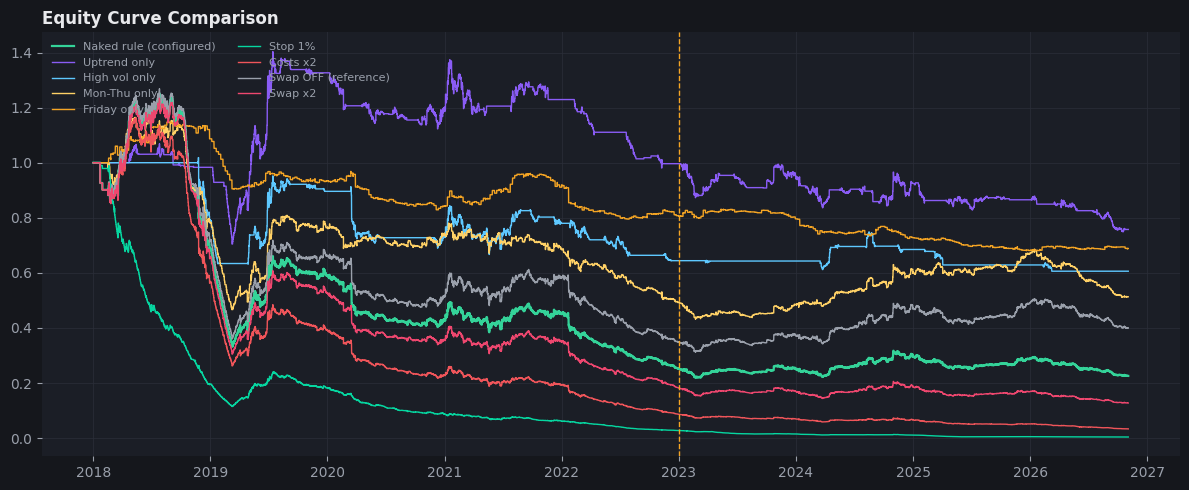

In [51]:
def run_with_swap(mult, **kw):
    sw = eng.ENGINE_DEFAULTS["swap_long_pct_annual"]
    eng.set_engine_defaults(swap_long_pct_annual=sw * mult)
    try:
        return eng.run_btcovn_backtest(df if not kw.get("_prep") else prep(df_raw, **kw["_prep"]), **{**RULES, **kw.get("rules", {})})
    finally:
        eng.set_engine_defaults(swap_long_pct_annual=sw)

variants = {"Naked rule (configured)": tr_full,
            "Uptrend only": tr_f["Uptrend only (open 00:00 > SMA)"],
            "High vol only": tr_f["High vol only (30d vol > past median)"],
            "Mon-Thu only": eng.run_btcovn_backtest(df, **{**RULES, "days": [0, 1, 2, 3]}),
            "Friday only": eng.run_btcovn_backtest(df, **{**RULES, "days": [4]}),
            "Stop 1%": tr_stop[1.0],
            "Costs x2": eng.run_btcovn_backtest(df, **{**RULES, "cost_bps_per_side": 2 * COST_BPS}),
            "Swap OFF (reference)": run_with_swap(0.0),
            "Swap x2": run_with_swap(2.0)}
rows, curves, raw = [], {}, {}
for name, t in variants.items():
    mt = compute_metrics(t, 1.0, 0.0)
    r = eng.hourly_returns(df, t, sizing="fraction")
    eq = (1 + r).cumprod()
    curves[name] = eq
    raw[name] = {"pf": mt["profit_factor"], "exp": mt["expectancy"], "sharpe": sharpe_ratio(dly(r), periods_per_year=PPY), "mdd": max_drawdown(eq), "final": float(eq.iloc[-1])}
    rows.append({"Variant": name, "Trades": mt["num_trades"], "Win Rate": f"{mt['win_rate']:.1f}%", "Profit Factor": f"{mt['profit_factor']:.3f}",
                 "Sharpe": f"{raw[name]['sharpe']:.2f}", "Max Drawdown": f"{raw[name]['mdd'] * 100:.2f}%", "Final Capital": f"{eq.iloc[-1]:.2f}x"})
print("=" * 80)
print(f"VARIANT COMPARISON ({SIZE_FRAC:.0%} capital per trade, {COST_BPS:g} bps/side)")
print("=" * 80)
display(pd.DataFrame(rows))

print("\nCHECKS (7):")
cf = raw["Naked rule (configured)"]
check("7. Variants", "Edge survives doubled costs (PF >= 1.05)", raw["Costs x2"]["pf"] >= 1.05, f"PF {raw['Costs x2']['pf']:.3f}")
check("7. Variants", "Edge survives a doubled swap (PF >= 1.05): the broker may change it", raw["Swap x2"]["pf"] >= 1.05, f"PF {raw['Swap x2']['pf']:.3f} (swap OFF {raw['Swap OFF (reference)']['pf']:.3f}, configured {cf['pf']:.3f})")
check("7. Variants", "Swap does not decide the verdict (configured PF >= 80% of the swap-free PF)", cf["pf"] >= 0.8 * raw["Swap OFF (reference)"]["pf"], f"{cf['pf']:.3f} vs {raw['Swap OFF (reference)']['pf']:.3f}")
check("7. Variants", "A 1% stop does not make the max drawdown worse", raw["Stop 1%"]["mdd"] >= cf["mdd"], f"stop {raw['Stop 1%']['mdd'] * 100:.2f}% vs none {cf['mdd'] * 100:.2f}%")

fig, ax = plt.subplots(figsize=(12, 5), facecolor=BG)
dark_ax(ax)
for (name, eq), col in zip(curves.items(), (GREEN, "#8a5cf5", "#5ec8ff", "#ffd166", ORANGE, "#06d6a0", RED, SUB, "#ef476f")):
    ax.plot(eq.index, eq, color=col, lw=1.6 if name.startswith("Naked") else 1.0, label=name)
ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.0)
ax.set_title("Equity Curve Comparison", color=TXT, fontweight="bold", loc="left"); ax.legend(frameon=False, labelcolor=SUB, fontsize=8, loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

## 8. SUMMARY OF HYPOTHESIS & NEXT STEPS

In [52]:
m_all, m_is, m_oos = (compute_metrics(t, 1.0, 0.0) for t in (trades_all, trades_is, trades_oos))
t_all = tstat(trades_all["pnl"])
max_dd_fr = max_drawdown((1 + eng.hourly_returns(df, trades_all, sizing="fraction")).cumprod()) * 100
years = (df.index[-1] - df.index[0]).days / 365.25
next_nb = "02_BTC_Overnight_Optimization.ipynb" if "parity_base" not in cfg else "04_BTC_Overnight_Reconciliation.ipynb"

confirmed = bool(m_all["profit_factor"] >= PF_MIN and m_oos["profit_factor"] >= PF_MIN and t_all >= T_MIN and m_all["num_trades"] >= N_MIN)
verdict = "Hypothesis Confirmed" if confirmed else "Hypothesis NOT clearly confirmed"
check("8. Verdict", f"Core criteria: PF >= {PF_MIN:g} (full and OOS), t >= {T_MIN:g}, N >= {N_MIN}", confirmed,
      f"PF {m_all['profit_factor']:.3f} / OOS {m_oos['profit_factor']:.3f} | t {t_all:.2f} | N {m_all['num_trades']}", quiet=True)

# ---- GO / STOP gate: only the checks that decide whether the research continues ----
ESSENTIAL = [
    ("3. Data",          "Prices are strictly positive",       "Fix the data first: every other number is invalid until this passes."),
    ("3. Data",          "Entry-hour bars exist",              "The CSV misses the entry-hour bars: re-export H1 history from the MT5 server."),
    ("3. Data",          "Server -> UTC conversion",           "The server offset is wrong: the 21-23 UTC window would be a different window. Fix server_ny_offset_h / server_tz."),
    ("6. Sanity",        "No lookahead and execution model",   "Fix the execution model / lookahead first: every other number is invalid until this passes."),
    ("6. Sanity",        "Placebo",                            "The engine finds an edge on random walks: it has a bias. Fix it first."),
    ("6. Sanity",        "No lookahead: truncating",           "The signal uses future data: fix prepare() before anything else."),
    ("6. Sanity",        "No lookahead in the trend",          "The trend / volatility filters use future data: fix prepare() before anything else."),
    ("4.1 Hour profile", "Entry-window hours are among the top", "The window is not special in this broker's data: check the server offset, then rethink the hypothesis."),
    ("4.1 Hour profile", "Window bars have a positive mean",   "The window mean is not significant: the seasonality is not in this data."),
    ("5. Baseline",      "Profit Factor, IS",                  "Baseline does not hold in-sample: the hypothesis is not supported, rethink the rules before optimizing."),
    ("5. Baseline",      "Profit Factor, OOS",                 "Baseline does not hold out-of-sample: do not optimize, the edge is not confirmed."),
    ("5. Baseline",      "t-stat of the mean trade",           "The mean trade is not statistically significant: the edge could be noise."),
    ("5. Baseline",      "Trades, full period",                "Too few trades to conclude anything: more history is needed."),
    ("5. Baseline",      "Trades, OOS",                        "Too few OOS trades to validate the edge."),
    ("4.4 Swap",         "Average swap drag",                  "The rollover swap eats the edge: move the window away from the rollover or do not trade this CFD."),
    ("7. Variants",      "Edge survives doubled costs",        "The edge does not survive 2x costs: the broker's spread decides whether it exists."),
    ("7. Variants",      "Edge survives a doubled swap",       "The edge does not survive a doubled swap: the broker's swap decides whether it exists."),
    ("5.1 Hard limit",   "Lot-adjusted sizing stays inside",   "Lot-adjusted sizing breaks the hard limit: add a stop, reduce the size fraction or raise capital."),
    ("5.1 Hard limit",   "Capital >= minimum capital for the minimum lot", "Capital is below what the minimum lot needs."),
    ("5.1 Hard limit",   "Every trade is executable",          "Some trades cannot be placed with the minimum lot at the configured fraction."),
    ("5.2 Annual",       "No calendar year breaches",          "A calendar year breaches the hard limit: review sizing, a stop, or the rules of that year."),
]
chk = pd.DataFrame(CHECKS)
n_pass, n_fail, n_skip = (int((chk["status"] == s).sum()) for s in ("PASS", "FAIL", "SKIP"))
key = {(s, n): a for s, n, a in ESSENTIAL}
chk["essential"] = [any(sec == s and nm.startswith(n) for s, n, _ in ESSENTIAL) for sec, nm in zip(chk["section"], chk["name"])]
ess = chk[chk["essential"]]
missing = [f"{s}: {n}" for s, n, _ in ESSENTIAL if not ((chk["section"] == s) & chk["name"].str.startswith(n)).any()]
ess_fail = ess[ess["status"] == "FAIL"]
go = ess_fail.empty and not missing

print("=" * 80)
print("8. SUMMARY OF HYPOTHESIS & NEXT STEPS")
print("=" * 80)
print(f"\nDECISION: {'GO - continue the research' if go else 'STOP - fix the failed gates before continuing'}   "
      f"({int((ess['status'] == 'PASS').sum())} PASS / {len(ess_fail)} FAIL / {int((ess['status'] == 'SKIP').sum())} SKIP of {len(ESSENTIAL)} essential checks)   |   {verdict}")
if missing:
    print("   Not run (run the sections above first): " + "; ".join(missing))
print("\n" + "-" * 80 + "\nESSENTIAL CHECKS\n" + "-" * 80)
for sec, g_ in ess.groupby("section", sort=False):
    print(f"\n{sec}")
    for _, row in g_.iterrows():
        print(f"   [{row['status']}] {row['name']}" + (f"  ->  {row['detail']}" if row["detail"] else ""))
print("\n" + "-" * 80 + "\nKEY FINDINGS\n" + "-" * 80)
print(f"""
1. {verdict}: {m_all['num_trades']} trades over {years:.0f}+ years, win rate {m_all['win_rate']:.1f}%, Profit Factor {m_all['profit_factor']:.3f}
   (IS {m_is['profit_factor']:.3f} / OOS {m_oos['profit_factor']:.3f}), t-stat of the mean trade {t_all:.2f}.

2. Hour profile: window bars {win_hours} mean {win_ret.mean():+.2f} bps per bar (t = {t_win:.2f}); best weekday by gross mean: {dw['gross_mean'].idxmax()}.

3. Swap: {sr['pct_crossing']:.0%} of the trades pay it, average drag {sr['avg_swap_drag_pct']:.4f}% per trade = {drag_share:.0%} of the gross mean; Friday x3 drag {sr['avg_drag_friday_pct']:.4f}%.

4. Risk at {SIZE_FRAC:.0%} sizing: max hourly-MTM drawdown {max_dd_fr:.2f}%; hard limit -{HARD_LIMIT:.0%}; the minimum lot weighs {min_lot_weight:.2f}x of the capital.
""")
print("-" * 80 + "\nNEXT STEPS\n" + "-" * 80)
steps = [key[(r["section"], next(n for s, n, _ in ESSENTIAL if s == r["section"] and r["name"].startswith(n)))] for _, r in ess_fail.iterrows()]
if missing:
    steps.append("Run all the sections above so every essential check is evaluated.")
if go:
    steps.append(f"Proceed to {next_nb}." + (" (vehicle variant: run section 10 first)" if "parity_base" in cfg else " Check that entry hour and holding time sit on a broad, stable plateau on in-sample data."))
for i, s in enumerate(steps, 1):
    print(f"{i}. {s}")

8. SUMMARY OF HYPOTHESIS & NEXT STEPS

DECISION: STOP - fix the failed gates before continuing   (10 PASS / 11 FAIL / 0 SKIP of 21 essential checks)   |   Hypothesis NOT clearly confirmed

--------------------------------------------------------------------------------
ESSENTIAL CHECKS
--------------------------------------------------------------------------------

3. Data
   [PASS] Prices are strictly positive  ->  min close 3173.48
   [FAIL] Entry-hour bars exist on >= 99% of days  ->  3181/3228 days have a 21:00 UTC bar (98.5%)
   [PASS] Server -> UTC conversion looks right: peak hourly volatility falls in 12-17 UTC (US / Europe overlap)  ->  peak volatility hour = 14:00 UTC (if far off, fix server_ny_offset_h in the YAML)

4.1 Hour profile
   [FAIL] Entry-window hours are among the top 4 hours by mean return  ->  ranks [5, 9] of 24
   [FAIL] Window bars have a positive mean with t >= 2  ->  mean +0.23 bps | t = 0.19

4.4 Swap
   [FAIL] Average swap drag <= 25% of the average gross

## 9. SAVE THE RESULTS OF THIS NOTEBOOK FOR THE VARIANT

In [53]:
limit_report = eng.hard_limit_report_intrabar(df, trades_all, HARD_LIMIT, lot_sizes["size_fraction"].to_numpy())
save_json(cfg, "01_hypothesis.json", {
    "variant": cfg["id"], "ticker": TICKER, "params": cfg["params"], "oos_start": str(oos_start.date()),
    "all": {"n": int(len(trades_all)), "pf": float(m_all["profit_factor"]), "win_rate": float(m_all["win_rate"]), "t_stat": float(t_all)},
    "is":  {"n": int(len(trades_is)),  "pf": float(m_is["profit_factor"])},
    "oos": {"n": int(len(trades_oos)), "pf": float(m_oos["profit_factor"])},
    "max_dd_fraction_sizing_pct": float(max_dd_fr),
    "hard_limit": {"limit": float(HARD_LIMIT), "max_dd_intrabar_pct": float(limit_report["max_dd"] * 100), "passed": bool(limit_report["passed"])},
    "min_capital": {"min_lot_weight": float(min_capital), "worst_gap": float(min_cap_gap), "min_lot_weight_of_capital": float(min_lot_weight)},
    "hour_profile": hp.reset_index().rename(columns={"index": "hour"}).to_dict(orient="records"),
    "weekday": dw.reset_index().to_dict(orient="records"),
    "filters": tbl43.reset_index().to_dict(orient="records"),
    "swap": {k: float(v) for k, v in sr.items()},
    "stop_sweep": stop_tbl.reset_index().to_dict(orient="records"),
    "hypothesis_confirmed": bool(confirmed),
    "checks_summary": {"pass": n_pass, "fail": n_fail, "skip": n_skip},
    "checks": CHECKS,
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/BTC_Overnight_Gap/runs/v1_btcusd_base/01_hypothesis.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/BTC_Overnight_Gap/runs/v1_btcusd_base/01_hypothesis.json')

## 10. VEHICLE PARITY VS THE BASE INSTRUMENT (ONLY FOR VEHICLE VARIANTS)
The research is done once on the base instrument. A vehicle (e.g. BTC-JPY) must only show that it trades **the same edge**: the same entries, the same price return per trade (a USD account's BTC-JPY P&L tracks BTCUSD to first order because the yen cancels), and an honest net difference from its own spread, swap and minimum lot. Skipped for the base variant.

In [54]:
if "parity_base" not in cfg:
    print("Base variant: nothing to compare. Run this notebook on a vehicle variant (e.g. v1_axi_btcjpy) to fill section 10.")
    check("10. Parity", "Parity with the base instrument", None, "base variant")
else:
    saved = dict(eng.ENGINE_DEFAULTS)
    base_cfg = load_variant(cfg["parity_base"])
    try:
        eng.set_engine_defaults(**base_cfg.get("engine_defaults", {}))
        b_raw = eng.load_data(base_cfg["instrument"]["ticker"], start=base_cfg["instrument"]["start"])
        b_df = eng.prepare(b_raw, **{k: base_cfg["params"][k] for k in eng.IND_KEYS})
        b_tr = eng.run_btcovn_backtest(b_df, **base_cfg["params"])
    finally:
        eng.ENGINE_DEFAULTS.clear(); eng.ENGINE_DEFAULTS.update(saved)
    v_tr = trades_all
    m = v_tr.merge(b_tr, on="entry_time", how="outer", suffixes=("_veh", "_base"), indicator=True)
    both = m[m["_merge"] == "both"].copy()
    gv = (both["exit_price_veh"] / both["entry_price_veh"] - 1) * 100
    gb = (both["exit_price_base"] / both["entry_price_base"] - 1) * 100
    corr = float(np.corrcoef(gv, gb)[0, 1]) if len(both) > 2 else np.nan
    print(f"Vehicle trades: {len(v_tr)} | base trades: {len(b_tr)} | matched by entry time: {len(both)}")
    print(f"Gross return per trade: vehicle {gv.mean():+.4f}% | base {gb.mean():+.4f}% | correlation {corr:.3f}")
    print(f"Net return per trade: vehicle {both['pnl_veh'].mean():+.4f}% | base {both['pnl_base'].mean():+.4f}% "
          f"(difference = spread {COST_BPS:g} vs {base_cfg['params']['cost_bps_per_side']:g} bps/side and swap {eng.ENGINE_DEFAULTS['swap_long_pct_annual']:g}% vs {base_cfg['engine_defaults']['swap_long_pct_annual']:g}%)")
    print("\nCHECKS (10):")
    check("10. Parity", "Entries matched by time on >= 95% of the vehicle's trades", len(both) / max(len(v_tr), 1) >= 0.95, f"{len(both) / max(len(v_tr), 1):.1%}")
    check("10. Parity", "Gross return per trade correlates >= 0.97 with the base (same edge)", corr >= 0.97, f"corr {corr:.3f}")
    check("10. Parity", "Mean gross return within 0.05 pts of the base", abs(gv.mean() - gb.mean()) <= 0.05, f"{gv.mean():+.4f}% vs {gb.mean():+.4f}%")
    check("10. Parity", "The vehicle's net mean per trade is still positive", both["pnl_veh"].mean() > 0, f"{both['pnl_veh'].mean():+.4f}%")

Base variant: nothing to compare. Run this notebook on a vehicle variant (e.g. v1_axi_btcjpy) to fill section 10.
   [SKIP] Parity with the base instrument  ->  base variant
